What This Notebook does
---
- explores the data

Insights
---
DATA IS UNIFORM  
Overall Background Info  
- 255347 rows and 18 cols
- mean/average default is 0.116128 --> 11.61% of the time loan was defaulted (failed to meet the repayment)
- looking at individuals ages 18 - 69
- uniform dataset
- Categorical Variables are about even as well is about 50-50
- no missing data
- no duplicates
- DTI(debt to income ration) = (total monthly debt payments/gross montly income) * 100 --> would prefer a lower dti

Predicting Default  
0-Did not default    225694  
1-did default     29653  
- Because we have very little data for those who did default, our model may have a harder time generalizing or detecting defaults because of the limited info



In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("../Loan_default.csv")

In [3]:
data.head(10)

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0
5,A9S62RQ7US,25,90298,90448,720,18,2,22.72,24,0.10,High School,Unemployed,Single,Yes,No,Business,Yes,1
6,H8GXPAOS71,38,111188,177025,429,80,1,19.11,12,0.16,Bachelor's,Unemployed,Single,Yes,No,Home,Yes,0
7,0HGZQKJ36W,56,126802,155511,531,67,4,8.15,60,0.43,PhD,Full-time,Married,No,No,Home,Yes,0
8,1R0N3LGNRJ,36,42053,92357,827,83,1,23.94,48,0.20,Bachelor's,Self-employed,Divorced,Yes,No,Education,No,1
9,CM9L1GTT2P,40,132784,228510,480,114,4,9.09,48,0.33,High School,Self-employed,Married,Yes,No,Other,Yes,0


In [4]:
data.columns

Index(['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore',
       'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm',
       'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus',
       'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner',
       'Default'],
      dtype='str')

What would be interesting about this dataset pertaining to loan default?
- ages could be interesting? Or at least knowing the range of ages could be helpful
- marital status could be interesting
- purpose of loans as well
- if they have a co signer, maybe we'll find if they do, they are less likely to default and vice versa
- ofc income

In [5]:
data.shape

(255347, 18)

In [6]:
data.dtypes

LoanID                str
Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education             str
EmploymentType        str
MaritalStatus         str
HasMortgage           str
HasDependents         str
LoanPurpose           str
HasCoSigner           str
Default             int64
dtype: object

In [7]:
data.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


In [8]:
data.isna().sum()

LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

In [9]:
data.duplicated().sum()

np.int64(0)

Checking out Age
---
- Ages range from 18 years old to 69 years old, every single age is included between the min and max
- each age range has approximately the same amount of data 

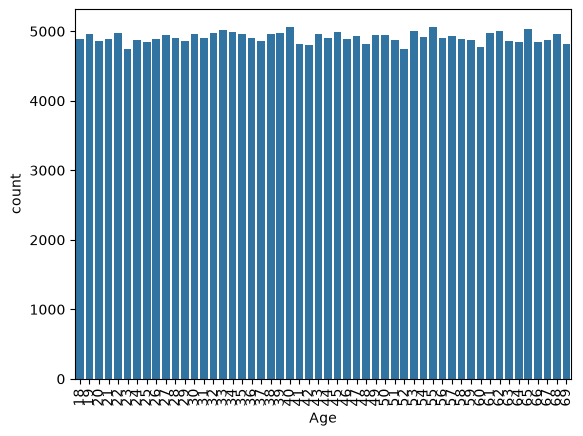

In [10]:
sns.countplot(data=data, x='Age')
plt.xticks(rotation=90)
plt.show()

In [11]:
ages = data['Age'].unique()
np.sort(ages)

array([18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51,
       52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68,
       69])

Income - Most frequent income amounts
---

In [12]:
data['Income'].value_counts().head(10)

Income
121985    10
69492     10
117102    10
149401     9
123299     9
23098      9
77704      9
95094      9
62823      9
118191     9
Name: count, dtype: int64

LoanAmount - most frequent loan amounts
---

In [13]:
data['LoanAmount'].value_counts().head(10)

LoanAmount
221949    8
133724    8
95419     8
183627    7
29290     7
111464    7
189116    7
179176    7
106920    7
202411    7
Name: count, dtype: int64

CreditScore
---

In [17]:
data['CreditScore'].value_counts().head(10)

CreditScore
630    528
445    521
829    520
753    519
670    515
347    514
643    514
775    512
362    510
628    508
Name: count, dtype: int64

Months Employed
---

In [23]:
data['MonthsEmployed'].value_counts()

MonthsEmployed
56     2227
26     2223
45     2220
107    2207
79     2198
       ... 
11     2043
39     2041
21     2014
99     2008
25     2004
Name: count, Length: 120, dtype: int64

In [22]:
data['InterestRate'].value_counts()

InterestRate
14.92    147
2.25     144
4.78     140
16.44    140
7.30     139
        ... 
15.50     83
4.58      82
14.34     81
25.00     53
2.00      44
Name: count, Length: 2301, dtype: int64

Default Variable 
---

In [14]:
data['Default'].value_counts()

Default
0    225694
1     29653
Name: count, dtype: int64

In [24]:
data['LoanTerm'].value_counts()

LoanTerm
48    51166
60    51154
36    51061
24    51009
12    50957
Name: count, dtype: int64

<Axes: xlabel='Default', ylabel='count'>

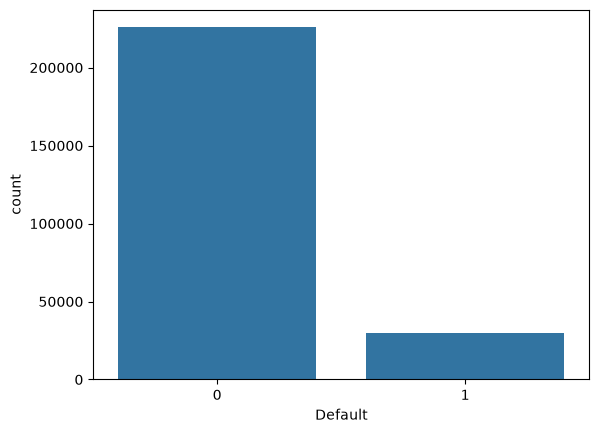

In [15]:
sns.countplot(data=data, x='Default')

Any Relationships?
---

In [33]:
data.groupby('EmploymentType')['Income'].median()
data.groupby('EmploymentType')['LoanAmount'].mean()
data.groupby('HasCoSigner')['LoanAmount'].mean()
data.groupby('NumCreditLines')['CreditScore'].mean()

NumCreditLines
1    574.314205
2    574.507953
3    573.614563
4    574.619781
Name: CreditScore, dtype: float64

In [35]:
data.groupby("Default")[
    ["Income", "LoanAmount", "CreditScore", "InterestRate"]
].mean()

,Income,LoanAmount,CreditScore,InterestRate
Default,,,,
0,83899.165995,125353.656017,576.232270,13.176994
1,71844.722659,144515.311469,559.286143,15.896227
